# Klasifikasi Gerakan Senam Berbasis IMU dan 1D CNN

Dataset primer: tiga gerakan, 11 subjek, sensor tangan kiri dan kaki kiri.
Alur: pra-pemrosesan (sinkronisasi, normalisasi, sliding window), model awal
1D CNN, optimasi hiperparameter, pemilihan model dengan macro F1 pada validasi
berbasis subjek, evaluasi LOSO, lalu analisis hasil.

## 1. Impor Library

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.models import Model
from tensorflow.keras import Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, f1_score, precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 2. Konfigurasi

Label gerakan diambil dari nama berkas.

In [3]:
import os

# ==============================
# Path dataset di Google Drive
# ==============================

DATA_DIR = "/content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/Dataset TA"

# Folder untuk menyimpan hasil
OUTPUT_DIR = "/content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==============================
# Kelas Gerakan
# ==============================

DAFTAR_GERAKAN = [
    "LIPAT PINGGANG",
    "JONGKOK 8 TITIK",
    "KOCOK SELURUH BADAN",
    "DIAM"
]

# ==============================
# File uji (opsional)
# ==============================

BERKAS_NGASAL = {
    "wearable_data_1784020709283_diam.csv": "DIAM",
}

# ==============================
# Sensor yang digunakan
# ==============================

# Karena dataset kamu memiliki magnetometer,
# saya sarankan gunakan semua sensor.

KOLOM_SENSOR = [
    "AX", "AY", "AZ",
    "GX", "GY", "GZ",
    "MX", "MY", "MZ"
]

# ==============================
# Parameter preprocessing
# ==============================

PERIODE_MS = 50          # 20 Hz
PANJANG_WINDOW = 44      # 44 sampel x 50 ms = 2,2 detik
LANGKAH_LATIH = 10
LANGKAH_UJI = 20
RASIO_VAL = 0.2
JUMLAH_SUBJEK_VALIDASI = 3

# ==============================
# Parameter training
# ==============================

EPOCH_CARI = 20
EPOCH_LOSO = 30
EPOCH_FINAL = 60
BATCH = 32

# ==============================
# Cek apakah folder ditemukan
# ==============================

print("DATA_DIR :", DATA_DIR)
print("Folder ditemukan :", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Isi folder:")
    print(os.listdir(DATA_DIR))

DATA_DIR : /content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/Dataset TA
Folder ditemukan : True
Isi folder:
['SONYA', 'WAYAN', 'CHAESA', 'ARUL', 'FAJAR', 'HAFIZH', 'NAUFAL', 'DEWA', 'REHAN', 'ATHAR', 'ADRIANSYAH']


## 3. Pra-pemrosesan: Sinkronisasi dan Ekstraksi Fitur

Kedua sensor dipisah lalu disinkronkan dengan resampling ke grid waktu 20 Hz.
Fitur yang dipakai magnitudo acc dan gyro per posisi (4 kanal) karena tidak
peka orientasi pemasangan sensor. Magnetometer tidak dipakai karena nilainya
dipengaruhi lingkungan, bukan gerakan.

In [4]:
def deteksi_bagian(device_id):
    nama = str(device_id).upper()
    if "KAKI" in nama:
        return "kaki"
    if "TANGAN" in nama:
        return "tangan"
    return None


def muat_rekaman(path):
    df = pd.read_csv(path)
    df.columns = ["Timestamp"] + list(df.columns[1:])  # perbaiki header korup
    df["Timestamp"] = pd.to_datetime(df["Timestamp"])
    df["bagian"] = df["DeviceID"].apply(deteksi_bagian)

    kanal = []
    for bagian in ["kaki", "tangan"]:
        sub = df[df["bagian"] == bagian].copy()
        if sub.empty:
            continue
        sub = sub.set_index("Timestamp").sort_index()
        sub = sub[KOLOM_SENSOR].resample(f"{PERIODE_MS}ms").mean().interpolate()
        sub.columns = [f"{kol}_{bagian}" for kol in KOLOM_SENSOR]
        kanal.append(sub)

    return pd.concat(kanal, axis=1).interpolate().dropna()


# Jendela untuk fitur turunan (rolling std, ZCR, energi)
JENDELA_TURUNAN = 10  # 10 sampel @ 20Hz = 0.5 detik


def fitur_magnitudo(df):
    fitur = {}
    for bagian in ["kaki", "tangan"]:
        for nama, awalan in [("acc", "A"), ("gyr", "G")]:
            kolom = [f"{awalan}{sumbu}_{bagian}" for sumbu in ["X", "Y", "Z"]]
            magnitudo = np.sqrt((df[kolom] ** 2).sum(axis=1))
            fitur[f"{nama}_{bagian}"] = magnitudo

            # Jerk: turunan sinyal -> menangkap perubahan mendadak
            fitur[f"{nama}_{bagian}_jerk"] = magnitudo.diff().fillna(0)

            # Rolling std: variabilitas sinyal dalam jendela pendek
            fitur[f"{nama}_{bagian}_std"] = (
                magnitudo.rolling(JENDELA_TURUNAN, min_periods=1).std().fillna(0)
            )

            # Zero-crossing rate: seberapa sering sinyal berganti tanda
            # setelah dikurangi rata-rata bergerak -> ciri gerakan berosilasi
            terpusat = magnitudo - magnitudo.rolling(
                JENDELA_TURUNAN, min_periods=1).mean()
            tanda_berubah = (np.sign(terpusat).diff().fillna(0) != 0).astype(float)
            fitur[f"{nama}_{bagian}_zcr"] = tanda_berubah.rolling(
                JENDELA_TURUNAN, min_periods=1).mean().fillna(0)

            # Energi: intensitas sinyal dalam jendela pendek
            fitur[f"{nama}_{bagian}_energi"] = (
                (magnitudo ** 2).rolling(JENDELA_TURUNAN, min_periods=1).mean().fillna(0)
            )

    return pd.DataFrame(fitur, index=df.index)


def label_dari_nama(nama_berkas):
    nama = nama_berkas.upper()
    for gerakan in DAFTAR_GERAKAN:
        if gerakan in nama:
            return gerakan
    return None

## 4. Muat Dataset Primer

In [5]:
rekaman = []
for subjek in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, subjek)
    if not os.path.isdir(folder):
        continue
    for berkas in sorted(os.listdir(folder)):
        if not berkas.lower().endswith(".csv"):
            continue
        gerakan = label_dari_nama(berkas)
        if gerakan is None:
            continue
        fitur = fitur_magnitudo(muat_rekaman(os.path.join(folder, berkas)))
        rekaman.append({"subjek": subjek, "gerakan": gerakan, "fitur": fitur})

daftar_subjek = sorted({r["subjek"] for r in rekaman})
kelas_ke_id = {nama: i for i, nama in enumerate(DAFTAR_GERAKAN)}
JUMLAH_KELAS = len(DAFTAR_GERAKAN)
KANAL = list(rekaman[0]["fitur"].columns)
JUMLAH_KANAL = len(KANAL)

inventaris = pd.crosstab(
    [r["subjek"] for r in rekaman],
    [r["gerakan"] for r in rekaman],
)
print(f"Jumlah rekaman: {len(rekaman)} dari {len(daftar_subjek)} subjek")
print(f"Kanal fitur ({JUMLAH_KANAL}): {KANAL}")
inventaris

Jumlah rekaman: 44 dari 11 subjek
Kanal fitur (20): ['acc_kaki', 'acc_kaki_jerk', 'acc_kaki_std', 'acc_kaki_zcr', 'acc_kaki_energi', 'gyr_kaki', 'gyr_kaki_jerk', 'gyr_kaki_std', 'gyr_kaki_zcr', 'gyr_kaki_energi', 'acc_tangan', 'acc_tangan_jerk', 'acc_tangan_std', 'acc_tangan_zcr', 'acc_tangan_energi', 'gyr_tangan', 'gyr_tangan_jerk', 'gyr_tangan_std', 'gyr_tangan_zcr', 'gyr_tangan_energi']


col_0,DIAM,JONGKOK 8 TITIK,KOCOK SELURUH BADAN,LIPAT PINGGANG
row_0,,,,
ADRIANSYAH,1,1,1,1
ARUL,1,1,1,1
ATHAR,1,1,1,1
CHAESA,1,1,1,1
DEWA,1,1,1,1
FAJAR,1,1,1,1
HAFIZH,1,1,1,1
NAUFAL,1,1,1,1
REHAN,1,1,1,1


## 5. Exploratory Data Analysis (EDA)

In [6]:
ringkas = pd.DataFrame([
    {
        "subjek": r["subjek"],
        "gerakan": r["gerakan"],
        "jumlah_sampel": len(r["fitur"]),
        "durasi_detik": round(len(r["fitur"]) * PERIODE_MS / 1000, 1),
    }
    for r in rekaman
])
ringkas.groupby("gerakan")[["jumlah_sampel", "durasi_detik"]].agg(["count", "mean", "min", "max"]).round(1)

jumlah_sampel                  durasi_detik              \
                            count   mean  min  max        count  mean   min   
gerakan                                                                       
DIAM                           11  351.7  340  382           11  17.6  17.0   
JONGKOK 8 TITIK                11  651.5  496  840           11  32.6  24.8   
KOCOK SELURUH BADAN            11  521.0  368  662           11  26.1  18.4   
LIPAT PINGGANG                 11  584.4  448  798           11  29.2  22.4   

                           
                      max  
gerakan                    
DIAM                 19.1  
JONGKOK 8 TITIK      42.0  
KOCOK SELURUH BADAN  33.1  
LIPAT PINGGANG       39.9

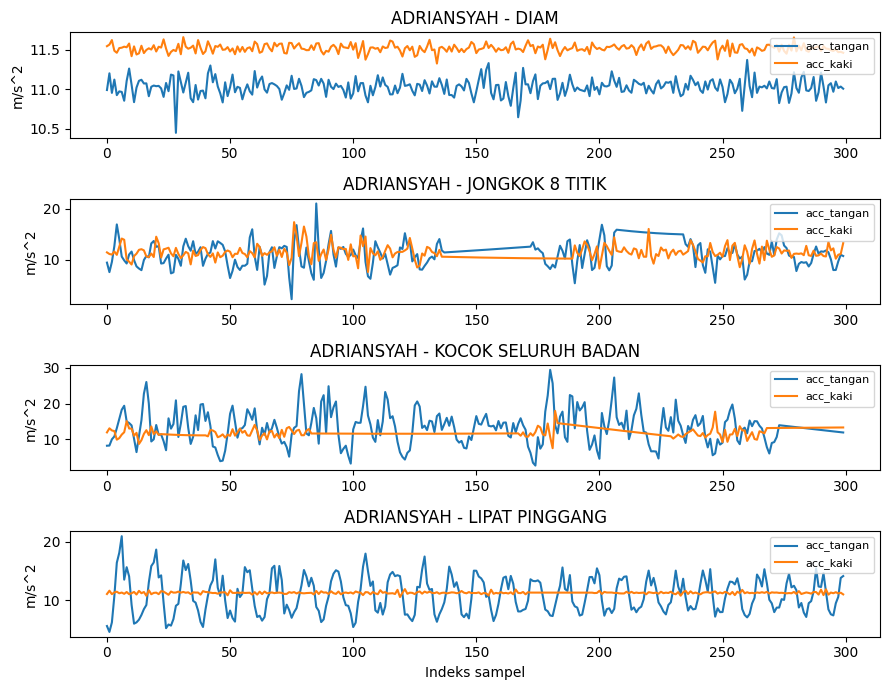

In [7]:
# Contoh sinyal fitur satu subjek untuk tiap gerakan
subjek_contoh = daftar_subjek[0]
contoh = [r for r in rekaman if r["subjek"] == subjek_contoh]

fig, axes = plt.subplots(len(contoh), 1, figsize=(9, 7))
for ax, r in zip(axes, contoh):
    potong = r["fitur"].iloc[:300]
    ax.plot(potong["acc_tangan"].values, label="acc_tangan")
    ax.plot(potong["acc_kaki"].values, label="acc_kaki")
    ax.set_title(f"{r['subjek']} - {r['gerakan']}")
    ax.set_ylabel("m/s^2")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Indeks sampel")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1474/288429126.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


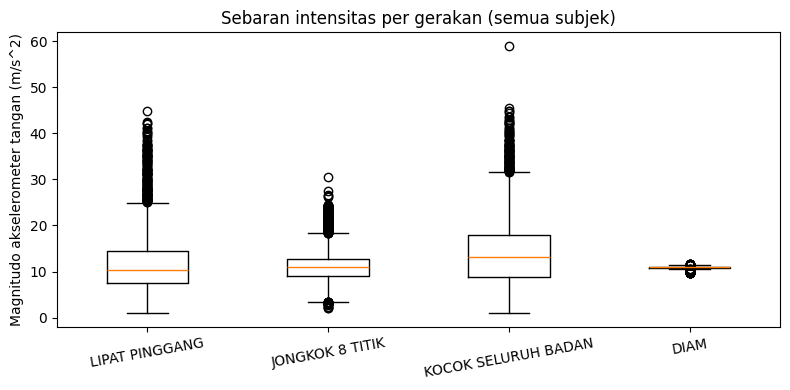

In [8]:
# Sebaran intensitas gerakan antar subjek
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(
    [
        np.concatenate([r["fitur"]["acc_tangan"].values for r in rekaman if r["gerakan"] == g])
        for g in DAFTAR_GERAKAN
    ],
    labels=DAFTAR_GERAKAN,
)
ax.set_ylabel("Magnitudo akselerometer tangan (m/s^2)")
ax.set_title("Sebaran intensitas per gerakan (semua subjek)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 6. Pra-pemrosesan: Normalisasi, Sliding Window, Augmentasi

In [9]:
def buat_window(matriks, panjang, langkah):
    if len(matriks) < panjang:
        return np.empty((0, panjang, matriks.shape[1]))
    batas = len(matriks) - panjang + 1
    return np.array([matriks[a:a + panjang] for a in range(0, batas, langkah)])


def kumpulkan_window(daftar_rekaman, scaler, panjang, langkah):
    X, y = [], []
    for r in daftar_rekaman:
        ternorm = scaler.transform(r["fitur"].values)
        window = buat_window(ternorm, panjang, langkah)
        if len(window) == 0:
            continue
        X.append(window)
        y.append(np.full(len(window), kelas_ke_id[r["gerakan"]]))
    return np.concatenate(X).astype("float32"), np.concatenate(y)


def augmentasi_jitter(X, sigma=0.05):
    return X + np.random.normal(0.0, sigma, X.shape).astype("float32")


def augmentasi_scaling(X, sigma=0.1):
    faktor = np.random.normal(1.0, sigma, (X.shape[0], 1, X.shape[2])).astype("float32")
    return X * faktor


def augmentasi(X, y):
    X_aug = np.concatenate([X, augmentasi_jitter(X), augmentasi_scaling(X)])
    y_aug = np.concatenate([y, y, y])
    acak = np.random.permutation(len(X_aug))
    return X_aug[acak], y_aug[acak]

## 7. Model Awal 1D CNN

Arsitektur diparameterkan agar hiperparameternya dapat dioptimasi.

In [10]:
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Bidirectional,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

HP_AWAL = {
    "lstm1": 64,
    "lstm2": 32,
    "dropout": 0.3,
    "lr": 1e-3,
    "panjang_window": 44,
}


def bangun_model(hp):

    input_layer = Input(
        shape=(hp["panjang_window"], JUMLAH_KANAL),
        name="Input"
    )

    x = Bidirectional(
        LSTM(
            units=hp["lstm1"],
            return_sequences=True,
            activation="tanh",
            recurrent_activation="sigmoid",
            kernel_regularizer=l2(1e-4)
        ),
        name="BiLSTM_1"
    )(input_layer)

    x = BatchNormalization()(x)
    x = Dropout(hp["dropout"])(x)

    x = Bidirectional(
        LSTM(
            units=hp["lstm2"],
            return_sequences=False,
            activation="tanh",
            recurrent_activation="sigmoid",
            kernel_regularizer=l2(1e-4)
        ),
        name="BiLSTM_2"
    )(x)

    x = BatchNormalization()(x)
    x = Dropout(hp["dropout"])(x)

    x = Dense(64, activation="relu")(x)
    x = Dropout(0.2)(x)

    output_layer = Dense(
        JUMLAH_KELAS,
        activation="softmax",
        name="Output"
    )(x)

    model = Model(
        inputs=input_layer,
        outputs=output_layer,
        name="BiLSTM_HAR"
    )

    model.compile(
        optimizer=Adam(learning_rate=hp["lr"], clipnorm=1.0),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = bangun_model(HP_AWAL)
model.summary()

Model: "BiLSTM_HAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 44, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BiLSTM_1 (Bidirectional)        │ (None, 44, 128)        │        43,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 44, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 44, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BiLSTM_2 (Bidirectional)        │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,924 (351.27 KB)

 Trainable params: 89,540 (349.77 KB)

 Non-trainable params: 384 (1.50 KB)

## 8. Optimasi Hiperparameter

Validasi berbasis subjek: beberapa subjek dipisahkan sepenuhnya dari pelatihan
dan hanya dipakai untuk menilai tiap kandidat hiperparameter dengan macro F1
per window.

In [12]:
# ============================================================
# HYPERPARAMETER SEARCH
# BASELINE TERBAIK + PERBANDINGAN WINDOW 40 vs 44
# ============================================================

# Konfigurasi terbaik dari eksperimen sebelumnya
HP_AWAL = {
    "lstm1": 128,
    "lstm2": 32,
    "dropout": 0.3,
    "lr": 1e-3,
    "panjang_window": 44,
}


# ============================================================
# PEMBAGIAN SUBJEK VALIDASI
# ============================================================

acak_subjek = np.random.RandomState(SEED).permutation(daftar_subjek)

SUBJEK_VALIDASI = sorted(
    acak_subjek[:JUMLAH_SUBJEK_VALIDASI]
)

SUBJEK_PENCARIAN = [
    s for s in daftar_subjek
    if s not in SUBJEK_VALIDASI
]

print("==============================================")
print("SUBJEK VALIDASI :", SUBJEK_VALIDASI)
print("SUBJEK PENCARIAN:", SUBJEK_PENCARIAN)
print("==============================================")


# ============================================================
# KANDIDAT YANG DIUJI
# HANYA MEMBANDINGKAN WINDOW 40 DAN 44
# DENGAN MODEL YANG SAMA
# ============================================================

KANDIDAT_HP = [HP_AWAL]


# ============================================================
# FUNGSI TRAINING + EVALUASI
# ============================================================

def latih_dan_nilai(
    hp,
    daftar_latih,
    daftar_uji,
    epoch
):

    # Reproducibility
    tf.random.set_seed(SEED)
    np.random.seed(SEED)

    # --------------------------------------------------------
    # SCALER
    # FIT HANYA PADA DATA TRAINING
    # --------------------------------------------------------

    scaler_hp = StandardScaler()

    scaler_hp.fit(
        np.vstack(
            [
                r["fitur"].values
                for r in daftar_latih
            ]
        )
    )

    # --------------------------------------------------------
    # BUAT WINDOW TRAINING
    # --------------------------------------------------------

    X_latih, y_latih = kumpulkan_window(
        daftar_latih,
        scaler_hp,
        hp["panjang_window"],
        LANGKAH_LATIH
    )

    # --------------------------------------------------------
    # AUGMENTASI
    # --------------------------------------------------------

    X_aug, y_aug = augmentasi(
        X_latih,
        y_latih
    )

    # --------------------------------------------------------
    # BANGUN MODEL
    # --------------------------------------------------------

    model_hp = bangun_model(hp)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    model_hp.fit(
        X_aug,
        to_categorical(
            y_aug,
            JUMLAH_KELAS
        ),
        epochs=epoch,
        batch_size=BATCH,
        verbose=0
    )

    # --------------------------------------------------------
    # WINDOW DATA VALIDASI
    # --------------------------------------------------------

    X_uji, y_uji = kumpulkan_window(
        daftar_uji,
        scaler_hp,
        hp["panjang_window"],
        LANGKAH_UJI
    )

    # --------------------------------------------------------
    # PREDIKSI
    # --------------------------------------------------------

    y_pred = model_hp.predict(
        X_uji,
        verbose=0
    ).argmax(axis=1)

    return (
        model_hp,
        scaler_hp,
        y_uji,
        y_pred
    )


# ============================================================
# DATA TRAINING DAN VALIDASI
# ============================================================

latih_cari = [
    r
    for r in rekaman
    if r["subjek"] in SUBJEK_PENCARIAN
]

uji_cari = [
    r
    for r in rekaman
    if r["subjek"] in SUBJEK_VALIDASI
]


# ============================================================
# JALANKAN EKSPERIMEN
# ============================================================

hasil_cari = []

for i, hp in enumerate(KANDIDAT_HP):

    print()
    print("==============================================")
    print(
        f"Eksperimen {i + 1}/{len(KANDIDAT_HP)}"
    )
    print("Window :", hp["panjang_window"])
    print("LSTM1  :", hp["lstm1"])
    print("LSTM2  :", hp["lstm2"])
    print("Dropout:", hp["dropout"])
    print("LR     :", hp["lr"])
    print("==============================================")

    (
        model_hp,
        scaler_hp,
        y_val,
        y_pred
    ) = latih_dan_nilai(
        hp,
        latih_cari,
        uji_cari,
        EPOCH_CARI
    )

    # --------------------------------------------------------
    # MACRO F1
    # --------------------------------------------------------

    macro_f1 = f1_score(
        y_val,
        y_pred,
        average="macro"
    )

    hasil_cari.append({
        **hp,
        "macro_f1": round(
            macro_f1,
            4
        )
    })

    print(
        f"Macro F1 = {macro_f1:.4f}"
    )


# ============================================================
# HASIL DALAM DATAFRAME
# ============================================================

hasil_cari = pd.DataFrame(
    hasil_cari
)


# ============================================================
# URUTKAN DARI F1 TERTINGGI
# ============================================================

hasil_urut = hasil_cari.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)


print()
print("==============================================")
print("HASIL WINDOW 44")
print("==============================================")

display(hasil_urut)


# ============================================================
# TAMPILKAN KONFIGURASI TERBAIK
# ============================================================

hasil_terbaik = hasil_urut.iloc[0]

print()
print("==============================================")
print("KONFIGURASI DENGAN MACRO F1 TERTINGGI")
print("==============================================")

print(
    f"LSTM1       : {hasil_terbaik['lstm1']}"
)

print(
    f"LSTM2       : {hasil_terbaik['lstm2']}"
)

print(
    f"Dropout     : {hasil_terbaik['dropout']}"
)

print(
    f"Learning Rate: {hasil_terbaik['lr']}"
)

print(
    f"Window      : {hasil_terbaik['panjang_window']}"
)

print(
    f"Macro F1    : {hasil_terbaik['macro_f1']:.4f}"
)

print("==============================================")

SUBJEK VALIDASI : [np.str_('ADRIANSYAH'), np.str_('FAJAR'), np.str_('SONYA')]
SUBJEK PENCARIAN: ['ARUL', 'ATHAR', 'CHAESA', 'DEWA', 'HAFIZH', 'NAUFAL', 'REHAN', 'WAYAN']

Eksperimen 1/1
Window : 44
LSTM1  : 128
LSTM2  : 32
Dropout: 0.3
LR     : 0.001
Macro F1 = 0.8542

HASIL WINDOW 44


,lstm1,lstm2,dropout,lr,panjang_window,macro_f1
0,128,32,0.3,0.001,44,0.8542



KONFIGURASI DENGAN MACRO F1 TERTINGGI
LSTM1       : 128.0
LSTM2       : 32.0
Dropout     : 0.3
Learning Rate: 0.001
Window      : 44.0
Macro F1    : 0.8542


## 9. Pemilihan Model

Kandidat dengan macro F1 tertinggi pada subjek validasi dipilih untuk evaluasi
LOSO.

In [13]:
hasil_cari_urut = (
    hasil_cari
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

HP_TERBAIK = {
    k: hasil_cari_urut.iloc[0][k]
    for k in [
        "lstm1",
        "lstm2",
        "lr",
        "dropout",
        "panjang_window"
    ]
}

HP_TERBAIK["lstm1"] = int(
    HP_TERBAIK["lstm1"]
)

HP_TERBAIK["lstm2"] = int(
    HP_TERBAIK["lstm2"]
)

HP_TERBAIK["panjang_window"] = PANJANG_WINDOW   # dikunci 44

print(
    "Hiperparameter terpilih:"
)

print(HP_TERBAIK)

display(
    hasil_cari_urut
)

Hiperparameter terpilih:
{'lstm1': 128, 'lstm2': 32, 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'panjang_window': 44}


,lstm1,lstm2,dropout,lr,panjang_window,macro_f1
0,128,32,0.3,0.001,44,0.8542


## 10. Evaluasi Leave-One-Subject-Out (LOSO)

Satu subjek bergiliran menjadi data uji, model dilatih dari nol pada subjek
lainnya dengan hiperparameter terpilih. Scaler di-fit ulang tiap fold hanya
dari subjek latih.

In [29]:

hasil_loso = []

for subjek_uji in daftar_subjek:

    # =====================================================
    # Leave-One-Subject-Out
    # =====================================================

    latih = [
        r for r in rekaman
        if r["subjek"] != subjek_uji
    ]

    uji = [
        r for r in rekaman
        if r["subjek"] == subjek_uji
    ]

    model_fold, scaler_fold, _, _ = latih_dan_nilai(
        HP_TERBAIK,
        latih,
        uji,
        EPOCH_LOSO
    )

    # =====================================================
    # Prediksi setiap rekaman
    # =====================================================

    for r in uji:

        ternorm = scaler_fold.transform(
            r["fitur"].values
        )

        window = buat_window(
            ternorm,
            HP_TERBAIK["panjang_window"],
            LANGKAH_UJI
        ).astype("float32")

        if len(window) == 0:
            continue

        # -------------------------------------------------
        # Prediksi setiap window
        # -------------------------------------------------

        prob = model_fold.predict(
            window,
            verbose=0
        )

        pred_window = prob.argmax(axis=1)  # tetap dihitung untuk kolom window_benar

        # -------------------------------------------------
        # AGREGASI / SOFT VOTING
        # Rata-ratakan probabilitas SEMUA window dulu,
        # baru ambil kelas dengan probabilitas tertinggi
        # -------------------------------------------------

        prob_rata = prob.mean(axis=0)

        id_pred = int(
            prob_rata.argmax()
        )

        # -------------------------------------------------
        # Jumlah window yang argmax-nya sama dgn kelas terpilih
        # (dipertahankan untuk keperluan pelaporan/analisis,
        # bukan lagi dasar keputusan)
        # -------------------------------------------------

        jumlah_window = len(pred_window)

        jumlah_voting = np.bincount(
            pred_window,
            minlength=JUMLAH_KELAS
        )

        window_terpilih = int(
            jumlah_voting[id_pred]
        )

        persentase_voting = (
            window_terpilih
            /
            jumlah_window
            *
            100
        )

        # -------------------------------------------------
        # Confidence = probabilitas rata-rata kelas terpilih
        # -------------------------------------------------

        confidence_rata = float(
            prob_rata[id_pred]
        ) * 100

        # -------------------------------------------------
        # Label asli
        # -------------------------------------------------

        label_asli = r["gerakan"]

        # -------------------------------------------------
        # Simpan hasil
        # -------------------------------------------------

        hasil_loso.append({

            "subjek": subjek_uji,

            "gerakan": label_asli,

            "prediksi": DAFTAR_GERAKAN[id_pred],

            "jumlah_window": jumlah_window,

            "window_terpilih": window_terpilih,

            "persentase_voting":
                round(persentase_voting, 2),

            "kemiripan_persen":
                round(confidence_rata, 2),

            "window_benar":
                int(
                    (
                        pred_window
                        ==
                        kelas_ke_id[label_asli]
                    ).sum()
                ),

            "benar":
                DAFTAR_GERAKAN[id_pred]
                ==
                label_asli
        })

    # =====================================================
    # Ringkasan per subjek
    # =====================================================

    hasil_subjek = [
        h for h in hasil_loso
        if h["subjek"] == subjek_uji
    ]

    n_benar = sum(
        h["benar"]
        for h in hasil_subjek
    )

    print(
        f"{subjek_uji}: "
        f"{n_benar}/{len(hasil_subjek)} "
        f"rekaman benar"
    )


hasil_loso = pd.DataFrame(hasil_loso)

print("\nHasil LOSO:")
display(hasil_loso)

ADRIANSYAH: 4/4 rekaman benar
ARUL: 3/4 rekaman benar
ATHAR: 4/4 rekaman benar
CHAESA: 4/4 rekaman benar
DEWA: 3/4 rekaman benar
FAJAR: 3/4 rekaman benar
HAFIZH: 4/4 rekaman benar
NAUFAL: 3/4 rekaman benar
REHAN: 4/4 rekaman benar
SONYA: 4/4 rekaman benar
WAYAN: 4/4 rekaman benar

Hasil LOSO:


,subjek,gerakan,prediksi,jumlah_window,window_terpilih,persentase_voting,kemiripan_persen,window_benar,benar
0,ADRIANSYAH,DIAM,DIAM,16,16,100.00,100.00,16,True
1,ADRIANSYAH,JONGKOK 8 TITIK,JONGKOK 8 TITIK,40,31,77.50,77.51,31,True
2,ADRIANSYAH,KOCOK SELURUH BADAN,KOCOK SELURUH BADAN,31,21,67.74,65.19,21,True
3,ADRIANSYAH,LIPAT PINGGANG,LIPAT PINGGANG,27,27,100.00,100.00,27,True
4,ARUL,DIAM,DIAM,17,17,100.00,100.00,17,True
5,ARUL,JONGKOK 8 TITIK,JONGKOK 8 TITIK,25,25,100.00,100.00,25,True
6,ARUL,KOCOK SELURUH BADAN,LIPAT PINGGANG,26,26,100.00,99.06,0,False
7,ARUL,LIPAT PINGGANG,LIPAT PINGGANG,26,24,92.31,93.58,24,True
8,ATHAR,DIAM,DIAM,16,16,100.00,100.00,16,True
9,ATHAR,JONGKOK 8 TITIK,JONGKOK 8 TITIK,28,28,100.00,100.00,28,True


## 11. Hasil

Accuracy, precision, recall, macro F1, confusion matrix, dan analisis per
subjek dihitung dari prediksi LOSO per rekaman.

In [32]:
y_asli = hasil_loso["gerakan"].map(kelas_ke_id)
y_pred = hasil_loso["prediksi"].map(kelas_ke_id)

akurasi = (y_asli == y_pred).mean()
presisi, recall, f1, _ = precision_recall_fscore_support(
    y_asli, y_pred, labels=range(JUMLAH_KELAS), average="macro", zero_division=0)
akurasi_window = hasil_loso["window_benar"].sum() / hasil_loso["jumlah_window"].sum()

print(f"Accuracy  : {akurasi * 100:.2f} persen "
      f"({int(hasil_loso['benar'].sum())}/{len(hasil_loso)} rekaman)")
print(f"Precision : {presisi * 100:.2f} persen (macro)")
print(f"Recall    : {recall * 100:.2f} persen (macro)")
print(f"Macro F1  : {f1 * 100:.2f} persen")
print(f"Akurasi per window: {akurasi_window * 100:.2f} persen")
print()

per_kelas = precision_recall_fscore_support(
    y_asli, y_pred, labels=range(JUMLAH_KELAS), zero_division=0)
tabel_kelas = pd.DataFrame({
    "gerakan": DAFTAR_GERAKAN,
    "precision": (per_kelas[0] * 100).round(1),
    "recall": (per_kelas[1] * 100).round(1),
    "f1": (per_kelas[2] * 100).round(1),
    "jumlah_rekaman": per_kelas[3],
})
tabel_kelas

Accuracy  : 90.91 persen (40/44 rekaman)
Precision : 90.91 persen (macro)
Recall    : 90.91 persen (macro)
Macro F1  : 90.91 persen
Akurasi per window: 85.71 persen



,gerakan,precision,recall,f1,jumlah_rekaman
0,LIPAT PINGGANG,81.8,81.8,81.8,11
1,JONGKOK 8 TITIK,90.9,90.9,90.9,11
2,KOCOK SELURUH BADAN,90.9,90.9,90.9,11
3,DIAM,100.0,100.0,100.0,11


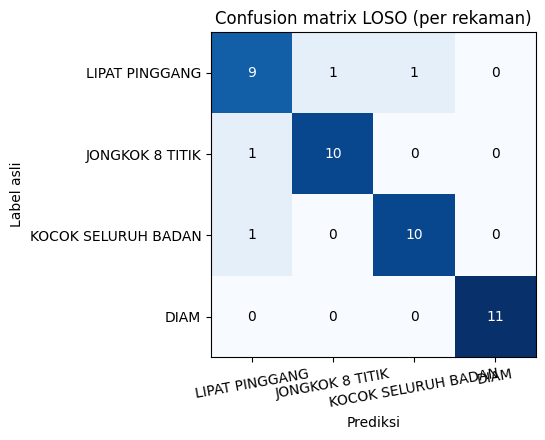

In [31]:

cm = confusion_matrix(y_asli, y_pred, labels=range(JUMLAH_KELAS))
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(JUMLAH_KELAS))
ax.set_xticklabels(DAFTAR_GERAKAN, rotation=10)
ax.set_yticks(range(JUMLAH_KELAS))
ax.set_yticklabels(DAFTAR_GERAKAN)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
ax.set_title("Confusion matrix LOSO (per rekaman)")
for i in range(JUMLAH_KELAS):
    for j in range(JUMLAH_KELAS):
        warna = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=warna)
plt.tight_layout()
plt.show()

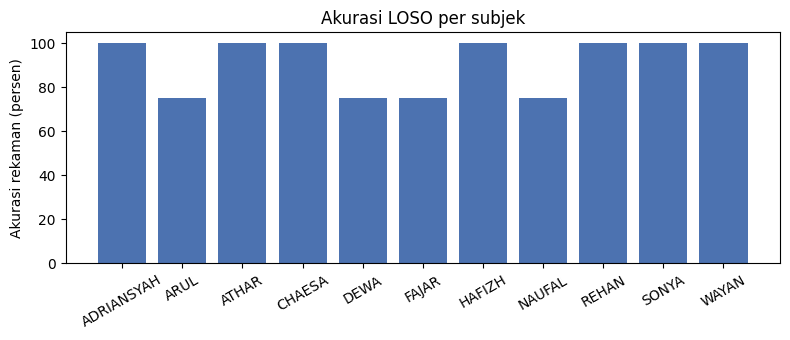

,rekaman_benar,jumlah_rekaman,akurasi_rekaman,akurasi_window
subjek,,,,
ADRIANSYAH,4,4,100.0,83.3
ARUL,3,4,75.0,70.2
ATHAR,4,4,100.0,98.9
CHAESA,4,4,100.0,95.7
DEWA,3,4,75.0,76.0
FAJAR,3,4,75.0,67.4
HAFIZH,4,4,100.0,97.6
NAUFAL,3,4,75.0,69.8
REHAN,4,4,100.0,98.2


In [33]:
# Analisis per subjek
per_subjek = hasil_loso.groupby("subjek").agg(
    rekaman_benar=("benar", "sum"),
    jumlah_rekaman=("benar", "size"),
    akurasi_window=("window_benar", "sum"),
    total_window=("jumlah_window", "sum"),
)
per_subjek["akurasi_rekaman"] = (
    per_subjek["rekaman_benar"] / per_subjek["jumlah_rekaman"] * 100).round(1)
per_subjek["akurasi_window"] = (
    per_subjek["akurasi_window"] / per_subjek["total_window"] * 100).round(1)
per_subjek = per_subjek[["rekaman_benar", "jumlah_rekaman", "akurasi_rekaman", "akurasi_window"]]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(per_subjek.index, per_subjek["akurasi_rekaman"], color="#4c72b0")
ax.set_ylabel("Akurasi rekaman (persen)")
ax.set_title("Akurasi LOSO per subjek")
ax.set_ylim(0, 105)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
per_subjek

## 12. Model Final

Dilatih pada seluruh subjek dengan hiperparameter terpilih untuk dipakai
memprediksi rekaman baru.

In [34]:
# ============================================================
# MODEL FINAL - STANDARDISASI TANPA DATA LEAKAGE
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.random.set_seed(SEED)
np.random.seed(SEED)

PANJANG_FINAL = HP_TERBAIK["panjang_window"]
LANGKAH_VAL = 10   # lebih rapat dari LANGKAH_UJI -> window validasi lebih banyak

# ------------------------------------------------------------
# 1. Kumpulkan fitur BAGIAN TRAINING saja untuk fitting scaler
# ------------------------------------------------------------

fitur_training_scaler = []

for r in rekaman:
    fitur = r["fitur"].values
    batas = int(len(fitur) * (1 - RASIO_VAL))

    # Hanya bagian training yang digunakan untuk fit scaler
    fitur_train = fitur[:batas]

    if len(fitur_train) > 0:
        fitur_training_scaler.append(fitur_train)

if not fitur_training_scaler:
    raise ValueError("Data training untuk StandardScaler kosong.")

scaler = StandardScaler()
scaler.fit(np.vstack(fitur_training_scaler))

print("StandardScaler berhasil di-fit menggunakan data training saja.")

# ------------------------------------------------------------
# 2. Transformasi dan pembentukan window
# ------------------------------------------------------------

Xt_list, yt_list = [], []
Xv_list, yv_list = [], []

for r in rekaman:
    fitur = r["fitur"].values
    batas = int(len(fitur) * (1 - RASIO_VAL))
    id_kelas = kelas_ke_id[r["gerakan"]]

    # Transformasi memakai scaler yang sudah di-fit pada training
    ternorm = scaler.transform(fitur)

    # Window training
    win_latih = buat_window(
        ternorm[:batas],
        PANJANG_FINAL,
        LANGKAH_LATIH
    )

    # Window validasi; jeda satu window dipertahankan
    # agar tidak berbagi sampel dengan bagian training
    win_val = buat_window(
        ternorm[batas + PANJANG_FINAL:],
        PANJANG_FINAL,
        LANGKAH_VAL
    )

    if len(win_latih) > 0:
        Xt_list.append(win_latih)
        yt_list.append(
            np.full(len(win_latih), id_kelas)
        )

    if len(win_val) > 0:
        Xv_list.append(win_val)
        yv_list.append(
            np.full(len(win_val), id_kelas)
        )

if not Xt_list or not Xv_list:
    raise ValueError(
        "Window training atau validasi kosong. "
        "Periksa panjang rekaman dan parameter window."
    )

X_latih = np.concatenate(Xt_list).astype("float32")
y_latih = np.concatenate(yt_list)

X_val = np.concatenate(Xv_list).astype("float32")
y_val = np.concatenate(yv_list)

print("Jumlah window training :", len(X_latih))
print("Jumlah window validasi :", len(X_val))
print("Bentuk X training      :", X_latih.shape)
print("Bentuk X validasi      :", X_val.shape)

# ------------------------------------------------------------
# 3. Augmentasi hanya pada data training
# ------------------------------------------------------------

X_aug, y_aug = augmentasi(X_latih, y_latih)

print("Jumlah window setelah augmentasi:", len(X_aug))

# ------------------------------------------------------------
# 4. Bangun dan latih model final
# ------------------------------------------------------------

model = bangun_model(HP_TERBAIK)

riwayat = model.fit(
    X_aug,
    to_categorical(y_aug, JUMLAH_KELAS),
    validation_data=(
        X_val,
        to_categorical(y_val, JUMLAH_KELAS)
    ),
    epochs=EPOCH_FINAL,
    batch_size=BATCH,
    callbacks=[
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-5,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=2
)

# ------------------------------------------------------------
# 5. Evaluasi validasi
# ------------------------------------------------------------

prediksi_val = model.predict(
    X_val,
    verbose=0
).argmax(axis=1)

akurasi_val = (prediksi_val == y_val).mean()

print(
    f"\nAkurasi validasi model final: "
    f"{akurasi_val * 100:.2f}%"
)

StandardScaler berhasil di-fit menggunakan data training saja.
Jumlah window training : 1686
Jumlah window validasi : 116
Bentuk X training      : (1686, 44, 20)
Bentuk X validasi      : (116, 44, 20)
Jumlah window setelah augmentasi: 5058
Epoch 1/60
159/159 - 35s - 220ms/step - accuracy: 0.8922 - loss: 0.3381 - val_accuracy: 0.9138 - val_loss: 0.2497 - learning_rate: 0.0010
Epoch 2/60
159/159 - 39s - 248ms/step - accuracy: 0.9336 - loss: 0.2171 - val_accuracy: 0.8966 - val_loss: 0.2610 - learning_rate: 0.0010
Epoch 3/60
159/159 - 24s - 153ms/step - accuracy: 0.9387 - loss: 0.1795 - val_accuracy: 0.8879 - val_loss: 0.2920 - learning_rate: 0.0010
Epoch 4/60
159/159 - 27s - 168ms/step - accuracy: 0.9342 - loss: 0.1731 - val_accuracy: 0.9052 - val_loss: 0.2065 - learning_rate: 0.0010
Epoch 5/60
159/159 - 25s - 157ms/step - accuracy: 0.9377 - loss: 0.1589 - val_accuracy: 0.9224 - val_loss: 0.1716 - learning_rate: 0.0010
Epoch 6/60
159/159 - 40s - 253ms/step - accuracy: 0.9375 - loss: 0.158

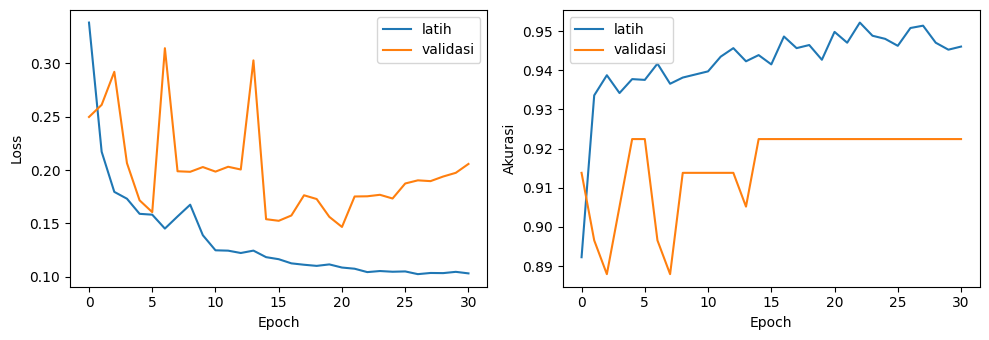

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(riwayat.history["loss"], label="latih")
axes[0].plot(riwayat.history["val_loss"], label="validasi")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(riwayat.history["accuracy"], label="latih")
axes[1].plot(riwayat.history["val_accuracy"], label="validasi")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Akurasi")
axes[1].legend()
plt.tight_layout()
plt.show()

## 13. Prediksi Tingkat Kemiripan

Prediksi akhir dari suara terbanyak antar window, tingkat kemiripan dari
rata-rata probabilitas gerakan terpilih.

In [38]:
def prediksi_kemiripan(
    path,
    baris_awal=100,
    baris_akhir=150
):

    # ==========================================
    # 1. Baca data
    # ==========================================
    fitur = fitur_magnitudo(
        muat_rekaman(path)
    )

    print("Total data tersedia:", len(fitur))

    # ==========================================
    # 2. Ambil DATA UJI SAJA
    # ==========================================
    fitur_uji = fitur.iloc[
        baris_awal:baris_akhir
    ].copy()

    print(
        f"Data uji: baris {baris_awal} "
        f"sampai {baris_akhir - 1}"
    )

    print(
        "Jumlah data uji:",
        len(fitur_uji)
    )

    # ==========================================
    # 3. Normalisasi
    # ==========================================
    ternorm = scaler.transform(
        fitur_uji.values
    )

    # ==========================================
    # 4. Buat window
    # ==========================================
    window = buat_window(
        ternorm,
        PANJANG_FINAL,
        LANGKAH_UJI
    ).astype("float32")

    if len(window) == 0:
        print(
            "Data uji tidak cukup untuk "
            "membentuk window."
        )
        return None

    print(
        "Jumlah window:",
        len(window)
    )

    # ==========================================
    # 5. Prediksi SETIAP window
    # ==========================================
    prob = model.predict(
        window,
        verbose=0
    )

    pred_per_window = prob.argmax(
        axis=1
    )

    # ==========================================
    # 6. Tampilkan urutan prediksi
    # ==========================================
    hasil_window = []

    for i, pred in enumerate(
        pred_per_window
    ):

        hasil_window.append({
            "window_ke": i + 1,
            "baris_mulai": (
                baris_awal +
                i * LANGKAH_UJI
            ),
            "prediksi": DAFTAR_GERAKAN[pred],
            "confidence_persen": round(
                float(prob[i, pred]) * 100,
                2
            )
        })

    tabel_window = pd.DataFrame(
        hasil_window
    )

    print("\nUrutan prediksi setiap window:")
    display(tabel_window)

    # ==========================================
    # 7. AGREGATOR / SOFT VOTING
    # Rata-ratakan probabilitas semua window dulu,
    # baru ambil kelas dengan probabilitas tertinggi
    # ==========================================
    prob_rata = prob.mean(axis=0)

    id_terpilih = int(
        prob_rata.argmax()
    )

    # ==========================================
    # 8. Skor tiap kelas = probabilitas rata-rata
    # ==========================================
    skor_voting = {
        nama: round(
            float(prob_rata[i]) * 100,
            2
        )
        for i, nama in enumerate(
            DAFTAR_GERAKAN
        )
    }

    # ==========================================
    # 9. Confidence = probabilitas rata-rata kelas terpilih
    # ==========================================
    confidence_rata = float(
        prob_rata[id_terpilih]
    ) * 100

    # ==========================================
    # 10. Hasil akhir
    # ==========================================
    hasil = {
        "prediksi": DAFTAR_GERAKAN[
            id_terpilih
        ],

        "kemiripan": round(
            float(confidence_rata),
            2
        ),

        "jumlah_window": len(
            pred_per_window
        ),

        "skor_voting": skor_voting,

        "tabel_window": tabel_window
    }

    print("\n==============================")
    print("HASIL AGREGASI")
    print("==============================")

    print(
        "Prediksi akhir :",
        hasil["prediksi"]
    )

    print(
        "Kemiripan      :",
        hasil["kemiripan"],
        "%"
    )

    print(
        "Jumlah window  :",
        hasil["jumlah_window"]
    )

    print("\nVoting:")
    for nama, skor in skor_voting.items():
        print(
            f"{nama}: {skor}%"
        )

    return hasil

## 14. Uji Gerakan Asal-asalan (Batasan Model)

Rekaman asal-asalan tetap mendapat skor tinggi ke kelas terdekat karena softmax
selalu memilih salah satu kelas. Skor kemiripan berarti "paling mirip gerakan
acuan yang mana", bukan ukuran benar tidaknya gerakan.

FILE TESTING
ncang_jongkok_8_titik_wearable_data_1781694210456.csv
ncang_lipat_pinggang_wearable_data_1781694323258.csv
ncang_kocok_seluruh_badan_wearable_data_1781694392121.csv
radit_jongkok_8_titik_wearable_data_1781694643236.csv
radit_lipat_pinggang_wearable_data_1781694744268.csv
radit_kocok_seluruh badan_wearable_data_1781694844290.csv
maulana_kocok_seluruh_badan_wearable_data_1781695280901.csv
widhi_jongkok_8_titik_wearable_data_1781695620977.csv
widhi_lipat_pinggang_wearable_data_1781695710688.csv
widhi_kocok_seluruh_badan_wearable_data_1781695871587.csv
zaki_jongkok_8_titik_wearable_data_1781696098904.csv
zaki_kocok_seluruh_badan_wearable_data_1781696765391.csv
DIAM.csv
testing diam.csv

Menguji: ncang_jongkok_8_titik_wearable_data_1781694210456.csv
Total data tersedia: 1069
Data uji: baris 100 sampai 149
Jumlah data uji: 50
Jumlah window: 1

Urutan prediksi setiap window:


,window_ke,baris_mulai,prediksi,confidence_persen
0,1,100,JONGKOK 8 TITIK,100.0



HASIL AGREGASI
Prediksi akhir : JONGKOK 8 TITIK
Kemiripan      : 100.0 %
Jumlah window  : 1

Voting:
LIPAT PINGGANG: 0.0%
JONGKOK 8 TITIK: 100.0%
KOCOK SELURUH BADAN: 0.0%
DIAM: 0.0%

Menguji: ncang_lipat_pinggang_wearable_data_1781694323258.csv
Total data tersedia: 590
Data uji: baris 100 sampai 149
Jumlah data uji: 50
Jumlah window: 1

Urutan prediksi setiap window:


,window_ke,baris_mulai,prediksi,confidence_persen
0,1,100,LIPAT PINGGANG,100.0



HASIL AGREGASI
Prediksi akhir : LIPAT PINGGANG
Kemiripan      : 100.0 %
Jumlah window  : 1

Voting:
LIPAT PINGGANG: 100.0%
JONGKOK 8 TITIK: 0.0%
KOCOK SELURUH BADAN: 0.0%
DIAM: 0.0%

Menguji: ncang_kocok_seluruh_badan_wearable_data_1781694392121.csv
Total data tersedia: 456
Data uji: baris 100 sampai 149
Jumlah data uji: 50
Jumlah window: 1

Urutan prediksi setiap window:


,window_ke,baris_mulai,prediksi,confidence_persen
0,1,100,LIPAT PINGGANG,50.38


... (22 outputs left out)


HASIL AGREGASI
Prediksi akhir : DIAM
Kemiripan      : 100.0 %
Jumlah window  : 1

Voting:
LIPAT PINGGANG: 0.0%
JONGKOK 8 TITIK: 0.0%
KOCOK SELURUH BADAN: 0.0%
DIAM: 100.0%

HASIL TESTING


,file,prediksi,kemiripan (%),jumlah_window,skor_LIPAT PINGGANG,skor_JONGKOK 8 TITIK,skor_KOCOK SELURUH BADAN,skor_DIAM
0,ncang_jongkok_8_titik_wearable_data_1781694210...,JONGKOK 8 TITIK,100.00,1,0.00,100.00,0.00,0.00
1,ncang_lipat_pinggang_wearable_data_17816943232...,LIPAT PINGGANG,100.00,1,100.00,0.00,0.00,0.00
2,ncang_kocok_seluruh_badan_wearable_data_178169...,LIPAT PINGGANG,50.38,1,50.38,0.00,49.61,0.01
3,radit_jongkok_8_titik_wearable_data_1781694643...,JONGKOK 8 TITIK,99.97,1,0.02,99.97,0.00,0.00
4,radit_lipat_pinggang_wearable_data_17816947442...,LIPAT PINGGANG,100.00,1,100.00,0.00,0.00,0.00
5,radit_kocok_seluruh badan_wearable_data_178169...,KOCOK SELURUH BADAN,100.00,1,0.00,0.00,100.00,0.00
6,maulana_kocok_seluruh_badan_wearable_data_1781...,KOCOK SELURUH BADAN,100.00,1,0.00,0.00,100.00,0.00
7,widhi_jongkok_8_titik_wearable_data_1781695620...,JONGKOK 8 TITIK,100.00,1,0.00,100.00,0.00,0.00
8,widhi_lipat_pinggang_wearable_data_17816957106...,LIPAT PINGGANG,99.99,1,99.99,0.01,0.00,0.00
9,widhi_kocok_seluruh_badan_wearable_data_178169...,KOCOK SELURUH BADAN,100.00,1,0.00,0.00,100.00,0.00




CONFUSION MATRIX MULTIKELAS

Tabel Confusion Matrix:


,LIPAT PINGGANG,JONGKOK 8 TITIK,KOCOK SELURUH BADAN,DIAM
LIPAT PINGGANG,3,0,0,0
JONGKOK 8 TITIK,0,4,0,0
KOCOK SELURUH BADAN,1,1,3,0
DIAM,0,0,0,2


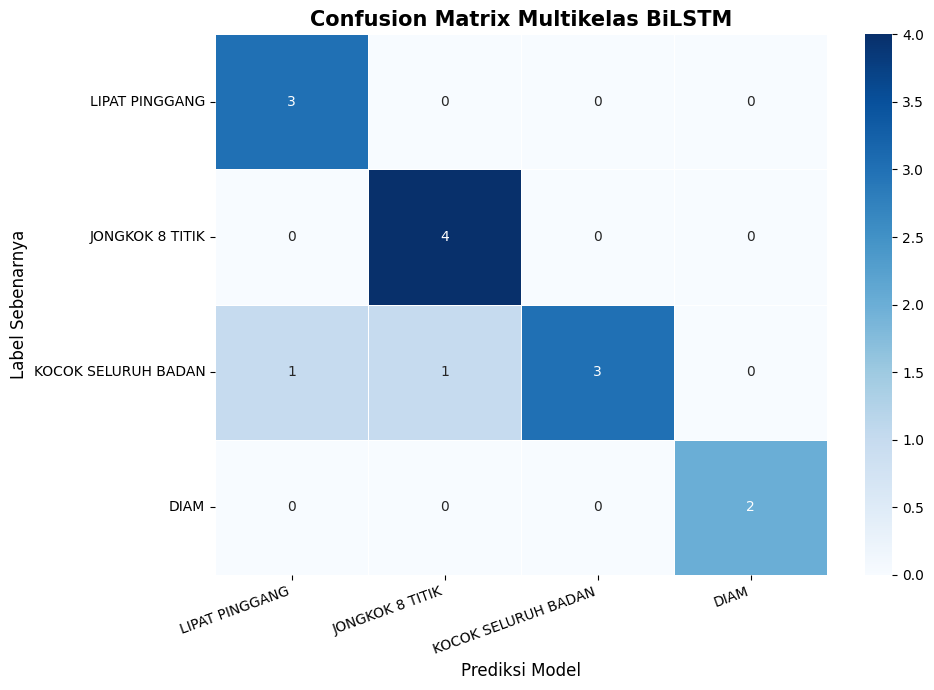



HASIL EVALUASI MULTIKELAS

Precision, Recall, F1-Score dan Support:


,precision,recall,f1-score,support
LIPAT PINGGANG,0.7500,1.0000,0.8571,3.0000
JONGKOK 8 TITIK,0.8000,1.0000,0.8889,4.0000
KOCOK SELURUH BADAN,1.0000,0.6000,0.7500,5.0000
DIAM,1.0000,1.0000,1.0000,2.0000
accuracy,0.8571,0.8571,0.8571,0.8571
macro avg,0.8875,0.9000,0.8740,14.0000
weighted avg,0.8893,0.8571,0.8484,14.0000



AKURASI KESELURUHAN MODEL
Accuracy : 85.71%

EVALUASI SETIAP KELAS


,Kelas,Precision (%),Recall (%),F1-Score (%),Jumlah Data
0,LIPAT PINGGANG,75.0,100.0,85.71,3
1,JONGKOK 8 TITIK,80.0,100.0,88.89,4
2,KOCOK SELURUH BADAN,100.0,60.0,75.00,5
3,DIAM,100.0,100.0,100.00,2


In [44]:

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_recall_fscore_support
)

# ==========================================================
# 1. KONFIGURASI
# ==========================================================

FOLDER_TESTING = "/content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/testing"

LABEL_KELAS = [
    "LIPAT PINGGANG",
    "JONGKOK 8 TITIK",
    "KOCOK SELURUH BADAN",
    "DIAM"
]

# ==========================================================
# 2. MEMBACA LABEL SEBENARNYA DARI NAMA FILE
# ==========================================================

def ambil_label_asli(nama_file):

    nama = os.path.basename(nama_file).lower()

    nama = re.sub(r'[^a-z0-9]+', '_', nama)

    if "lipat_pinggang" in nama:
        return "LIPAT PINGGANG"

    elif "jongkok_8_titik" in nama:
        return "JONGKOK 8 TITIK"

    elif "kocok_seluruh_badan" in nama:
        return "KOCOK SELURUH BADAN"

    elif nama in ["diam.csv", "testing.csv"]:
        return "DIAM"

    elif "diam" in nama:
        return "DIAM"

    return None


# ==========================================================
# 3. MENGAMBIL SEMUA FILE CSV
# ==========================================================

BERKAS_NGASAL = {}

for root, dirs, files in os.walk(FOLDER_TESTING):

    for file in files:

        if file.lower().endswith(".csv"):

            berkas = os.path.join(root, file)

            BERKAS_NGASAL[berkas] = True


print("==========================================")
print("FILE TESTING")
print("==========================================")

if len(BERKAS_NGASAL) == 0:

    print("Tidak ada file CSV di folder testing.")


else:

    for berkas in BERKAS_NGASAL:

        print(os.path.basename(berkas))


# ==========================================================
# 4. PREDIKSI SEMUA FILE TESTING
# ==========================================================

hasil_testing = []

for berkas in BERKAS_NGASAL:

    if not os.path.exists(berkas):
        continue

    nama_file = os.path.basename(berkas)

    print("\n==============================")
    print("Menguji:", nama_file)
    print("==============================")

    # Label sebenarnya
    label_asli = ambil_label_asli(nama_file)

    if label_asli is None:

        print("PERINGATAN: Label asli tidak dikenali:", nama_file)

        continue

    # Prediksi model
    hasil = prediksi_kemiripan(
        berkas,
        baris_awal=100,
        baris_akhir=150
    )

    if hasil is None:

        print("Prediksi gagal:", nama_file)

        continue

    prediksi = str(hasil["prediksi"]).strip().upper()

    if prediksi not in LABEL_KELAS:

        print("Label prediksi tidak dikenal:", prediksi)

        continue

    # Menyimpan hasil
    baris = {

        "file": nama_file,

        "label_asli": label_asli,

        "prediksi": prediksi,

        "kemiripan (%)": hasil["kemiripan"],

        "jumlah_window": hasil["jumlah_window"]

    }

    # Menambahkan skor voting semua kelas
    for nama, skor in hasil["skor_voting"].items():

        baris[f"skor_{nama}"] = skor

    hasil_testing.append(baris)


# ==========================================================
# 5. MEMBUAT DATAFRAME HASIL TESTING
# ==========================================================

hasil_testing = pd.DataFrame(hasil_testing)


# ==========================================================
# 6. FORMAT DATA
# ==========================================================

if not hasil_testing.empty:

    kolom_angka = ["kemiripan (%)"]

    kolom_angka += [
        kolom for kolom in hasil_testing.columns
        if kolom.startswith("skor_")
    ]

    for kolom in kolom_angka:

        hasil_testing[kolom] = pd.to_numeric(
            hasil_testing[kolom],
            errors="coerce"
        ).round(2)


# ==========================================================
# 7. MENAMPILKAN HASIL TESTING
# ==========================================================

print("\n==========================================")
print("HASIL TESTING")
print("==========================================")

if hasil_testing.empty:

    print("Tidak ada hasil testing yang berhasil.")

else:

    # Tampilan menyerupai screenshot
    kolom_tampil = [
        "file",
        "prediksi",
        "kemiripan (%)",
        "jumlah_window"
    ]

    kolom_tampil += [
        f"skor_{kelas}" for kelas in LABEL_KELAS
        if f"skor_{kelas}" in hasil_testing.columns
    ]

    display(
        hasil_testing[kolom_tampil].reset_index(drop=True)
    )


# ==========================================================
# 8. CONFUSION MATRIX MULTIKELAS
# ==========================================================

print("\n")
print("=" * 65)
print("CONFUSION MATRIX MULTIKELAS")
print("=" * 65)

if not hasil_testing.empty:

    y_true = hasil_testing["label_asli"]

    y_pred = hasil_testing["prediksi"]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=LABEL_KELAS
    )

    # Menampilkan confusion matrix
    cm_df = pd.DataFrame(
        cm,
        index=LABEL_KELAS,
        columns=LABEL_KELAS
    )

    print("\nTabel Confusion Matrix:")
    display(cm_df)

    # Visualisasi
    plt.figure(figsize=(10, 7))

    sns.heatmap(
        cm_df,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        cbar=True
    )

    plt.title(
        "Confusion Matrix Multikelas BiLSTM",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "Prediksi Model",
        fontsize=12
    )

    plt.ylabel(
        "Label Sebenarnya",
        fontsize=12
    )

    plt.xticks(rotation=20, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()


# ==========================================================
# 9. CLASSIFICATION REPORT
# ==========================================================

print("\n")
print("=" * 65)
print("HASIL EVALUASI MULTIKELAS")
print("=" * 65)

if not hasil_testing.empty:

    report = classification_report(
        y_true,
        y_pred,
        labels=LABEL_KELAS,
        target_names=LABEL_KELAS,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    print("\nPrecision, Recall, F1-Score dan Support:")

    display(
        report_df.round(4)
    )


# ==========================================================
# 10. AKURASI KESELURUHAN
# ==========================================================

if not hasil_testing.empty:

    akurasi = accuracy_score(
        y_true,
        y_pred
    )

    print("\n==========================================")
    print("AKURASI KESELURUHAN MODEL")
    print("==========================================")

    print(f"Accuracy : {akurasi * 100:.2f}%")


# ==========================================================
# 11. EVALUASI SETIAP KELAS
# ==========================================================

if not hasil_testing.empty:

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_KELAS,
            zero_division=0
        )
    )

    evaluasi_per_kelas = pd.DataFrame({

        "Kelas": LABEL_KELAS,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "F1-Score (%)": f1 * 100,

        "Jumlah Data": support

    })

    evaluasi_per_kelas[
        ["Precision (%)", "Recall (%)", "F1-Score (%)"]
    ] = evaluasi_per_kelas[
        ["Precision (%)", "Recall (%)", "F1-Score (%)"]
    ].round(2)

    print("\n==========================================")
    print("EVALUASI SETIAP KELAS")
    print("==========================================")

    display(evaluasi_per_kelas)


## 15. Ekspor Model dan Hasil

In [45]:
path_model = os.path.join(OUTPUT_DIR, "model_cnn_har.h5")
path_scaler = os.path.join(OUTPUT_DIR, "parameter_scaler.npz")
path_hp = os.path.join(OUTPUT_DIR, "hasil_pencarian_hp.csv")
path_loso = os.path.join(OUTPUT_DIR, "hasil_loso.csv")
path_ngasal = os.path.join(OUTPUT_DIR, "hasil_uji_ngasal.csv")

model.save(path_model)
np.savez(
    path_scaler,
    mean=scaler.mean_,
    scale=scaler.scale_,
    kanal=np.array(KANAL),
    kelas=np.array(DAFTAR_GERAKAN),
)
hasil_cari_urut.to_csv(path_hp, index=False)
hasil_loso.to_csv(path_loso, index=False)
hasil_testing.to_csv(path_ngasal, index=False)   # <- diganti dari hasil_ngasal

print("Berkas tersimpan:")
for p in [path_model, path_scaler, path_hp, path_loso, path_ngasal]:
    print(f"  {p}")

Berkas tersimpan:
  /content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/output/model_cnn_har.h5
  /content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/output/parameter_scaler.npz
  /content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/output/hasil_pencarian_hp.csv
  /content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/output/hasil_loso.csv
  /content/drive/MyDrive/Optimalisasi Model BiLSTM untuk Pengenalan Gerakan Ling Tien Kung Berbasis Data Sensor Wearable/output/hasil_uji_ngasal.csv


In [ ]:
x